# Vessel Segmentation — DeepLabV3+ Inference

**Inference-only notebook** — loads an already-trained DeepLabV3+ checkpoint
and runs it against the held-out `Testing/` split, per project guide Section
3 ("test/Testing folder: untouched until final evaluation").

**Assumed architecture** (edit Section 2 below if your checkpoint differs):
`segmentation_models_pytorch.DeepLabV3Plus(encoder_name="resnet34",
encoder_weights=None, classes=5)`. The project guide's other runs (Runs 1-2)
use `smp.UnetPlusPlus` with a ResNet34 encoder in the same style, so this
follows that same convention for consistency — if your DeepLab checkpoint was
trained with a different encoder (e.g. `resnet50`, `mobilenet_v2`) or a
different `smp` DeepLab variant, change `ENCODER_NAME` / the model
constructor in Section 2 and nothing else needs to change.

**What this notebook does:**
1. Loads the checkpoint and rebuilds the exact preprocessing pipeline used in
   Runs 1-3 (resize-before-color-match RGB masks, same 5 class colors).
2. Runs inference over `Testing/testset_images` + `Testing/testset_masks`.
3. Computes Dice, IoU, TPR, and ASSD per class (project guide Section 12),
   using the actual effective resolution (**~0.91 µm/px**, not the raw
   0.227 µm/px native resolution — Section 12 explicitly flags this as the
   correct conversion factor after the 4x downsample).
4. Saves a confusion matrix, a metrics CSV/JSON, and a handful of
   image/GT/prediction visual comparisons.
5. Zips results for the manual Kaggle → Drive merge (Section 11).


## 0. Environment & path discovery

In [2]:
!pip install -q segmentation-models-pytorch


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 2.9 MB/s eta 0:00:00a 0:00:01


In [3]:
import os, glob, json, time, zipfile
import numpy as np
import cv2
import torch
import torch.nn.functional as F

print(torch.__version__, "| CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))


2.10.0+cu128 | CUDA available: True
Tesla T4


In [4]:
# Don't assume the flat /kaggle/input/<slug>/ layout -- confirm it (Section 16, item 2).
!find /kaggle/input -maxdepth 4


/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/zakariaassadiki
/kaggle/input/datasets/zakariaassadiki/run4-deeplab
/kaggle/input/datasets/zakariaassadiki/run4-deeplab/kaggle
/kaggle/input/datasets/zakariaassadiki/vessel-dataset
/kaggle/input/datasets/zakariaassadiki/vessel-dataset/VascularModelDataset


In [5]:
# EDIT THESE after inspecting the find output above.
DATASET_ROOT = "/kaggle/input/datasets/zakariaassadiki/vessel-dataset/VascularModelDataset"
TEST_PATCH_DIR = os.path.join(DATASET_ROOT, "Testing", "testset_images")
TEST_MASK_DIR  = os.path.join(DATASET_ROOT, "Testing", "testset_masks")

# EDIT THIS to point at your trained DeepLab checkpoint (state_dict .pt/.pth file).
# If it came from the SegFormer/Run-7 style workflow it'll be sitting under
# /kaggle/input/<your-checkpoint-dataset>/ if you attached it as a Kaggle Dataset,
# or under /kaggle/working/checkpoints/ if it's from earlier in this same session.
CHECKPOINT_PATH = "/kaggle/input/datasets/zakariaassadiki/run4-deeplab/kaggle/working/checkpoints/vessel_run4_deeplabv3plus_augON.pth"

WORK_DIR = "/kaggle/working"
RESULTS_DIR = os.path.join(WORK_DIR, "deeplab_inference_results")
os.makedirs(RESULTS_DIR, exist_ok=True)

print("test patches:", len(glob.glob(os.path.join(TEST_PATCH_DIR, "*.tiff"))))
print("test masks  :", len(glob.glob(os.path.join(TEST_MASK_DIR, "*.tiff"))))
print("checkpoint exists:", os.path.exists(CHECKPOINT_PATH))


test patches: 728
test masks  : 728
checkpoint exists: True


## 1. Constants — same 5 classes / colors as Runs 1-3, and the effective µm/px

**Important fix:** `Testing/` masks encode background as **white**
`(255,255,255)`, while `Training/` masks encode background as **black**
`(0,0,0)` (confirmed in Section 1 of the project guide, and re-confirmed by
direct pixel inspection when this discrepancy was tracked down). Nearest-color
classification against only the black reference color misclassifies every
white background pixel as `bile_duct` -- purple `(128,0,128)` happens to be
the *closest* of the 5 pure class colors to white, closer even than black
itself. A patch that's genuinely 100% background then reads as 100%
bile_duct, which is exactly the ~45% degenerate-mask pattern found in Section
3e below.

**Fix:** treat both black and white as valid background reference colors when
nearest-color-matching, rather than assuming one fixed convention.

In [6]:
CLASS_COLORS = np.array([
    [0,   0,   0],    # 0 background (black -- Training/ convention)
    [0,   0, 255],    # 1 portal vein
    [0, 255,   0],    # 2 central vein
    [255,  0,   0],   # 3 hepatic artery
    [128,  0, 128],   # 4 bile duct
], dtype=np.uint8)
NUM_CLASSES = len(CLASS_COLORS)
CLASS_NAMES = ["background", "portal_vein", "central_vein", "artery", "bile_duct"]

# Extended reference set used ONLY for nearest-color matching: background gets
# a second reference color (white, Testing/'s convention). Both map to class 0.
# This makes classification convention-agnostic instead of assuming one file's
# background color applies to every mask in the dataset.
_MATCH_COLORS = np.array([
    [0,   0,   0],    # -> class 0 (background, black)
    [255, 255, 255],  # -> class 0 (background, white)
    [0,   0, 255],    # -> class 1
    [0, 255,   0],    # -> class 2
    [255,  0,   0],   # -> class 3
    [128,  0, 128],   # -> class 4
], dtype=np.uint8)
_MATCH_COLOR_TO_CLASS = np.array([0, 0, 1, 2, 3, 4])

PATCH_SIZE = 256           # target resolution used for training (4x downsample from 1024)
BATCH_SIZE = 16

# Native slide resolution is 0.227 um/px (Section 1). After the 4x downsample
# to 256x256 the *effective* resolution is ~0.91 um/px (Section 2) -- use this
# for ASSD, not the raw native value (Section 12 flags this explicitly).
UM_PER_PX = 0.227 * 4  # ~0.908


## 2. Model — rebuild architecture, then load the checkpoint

In [7]:
import zipfile

# Verify the checkpoint file before attempting to load it -- an IndexError /
# "list index out of range" / "invalid magic number" during torch.load almost
# always means a truncated or corrupted file (interrupted download, partial
# Drive sync, or a Kaggle session wiped mid-transfer -- Section 11 flags this
# exact risk), not a code problem. Cheaper to catch here than from a stack trace.
if not os.path.exists(CHECKPOINT_PATH):
    raise FileNotFoundError(f"CHECKPOINT_PATH does not exist: {CHECKPOINT_PATH}")

size_mb = os.path.getsize(CHECKPOINT_PATH) / 1e6
print(f"Checkpoint file size: {size_mb:.1f} MB")
# A DeepLabV3+ / resnet34 / 5-class state_dict saved with torch.save is
# typically in the tens of MB range. A file that's suspiciously small
# (a few KB, or 0 bytes) is a dead giveaway of a failed transfer.
if size_mb < 1:
    print("WARNING: file is under 1 MB -- almost certainly truncated/incomplete, not a real checkpoint.")

# torch.save's default format is a zip archive -- check it's actually a valid one.
is_valid_zip = zipfile.is_zipfile(CHECKPOINT_PATH)
print(f"Valid zip-format checkpoint: {is_valid_zip}")
if not is_valid_zip:
    print("WARNING: not a valid zip archive -- the file is corrupted or was saved in an")
    print("unexpected format (e.g. an old torch.save(..., _use_new_zipfile_serialization=False),")
    print("or the download/transfer was interrupted partway through.")


Checkpoint file size: 89.9 MB
Valid zip-format checkpoint: True


In [8]:
import segmentation_models_pytorch as smp

ENCODER_NAME = "resnet34"  # edit if your checkpoint used a different encoder

model = smp.DeepLabV3Plus(
    encoder_name=ENCODER_NAME,
    encoder_weights=None,   # weights come from the checkpoint, not ImageNet, at load time
    classes=NUM_CLASSES,
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
state_dict = torch.load(CHECKPOINT_PATH, map_location=device)
# handles both a raw state_dict and a {"model_state_dict": ...} wrapper
if isinstance(state_dict, dict) and "model_state_dict" in state_dict:
    state_dict = state_dict["model_state_dict"]
model.load_state_dict(state_dict)
model = model.to(device)
model.eval()

n_params = sum(p.numel() for p in model.parameters())
print(f"DeepLabV3+ ({ENCODER_NAME}) params: {n_params/1e6:.1f}M -- loaded from {CHECKPOINT_PATH}")


DeepLabV3+ (resnet34) params: 22.4M -- loaded from /kaggle/input/datasets/zakariaassadiki/run4-deeplab/kaggle/working/checkpoints/vessel_run4_deeplabv3plus_augON.pth


## 3. Preprocessing — identical resize-before-color-match pipeline as training

Same as Runs 1-3 / the SegFormer run: resize first (nearest-neighbor for the
mask, so no anti-aliased colors are introduced), *then* classify against the
5 pure RGB colors on the already-small array (Section 2 / Section 16 item 4 —
doing this at full 1024x1024 was the original bottleneck).

In [9]:
def rgb_mask_to_class_index(mask_rgb, match_colors=_MATCH_COLORS, match_to_class=_MATCH_COLOR_TO_CLASS):
    # NOTE: this now actually uses the extended 6-color match set defined in
    # Cell 7 (_MATCH_COLORS / _MATCH_COLOR_TO_CLASS), which maps BOTH black
    # and white to class 0 (background). The earlier version of this function
    # defaulted to the plain 5-color CLASS_COLORS (black-only background),
    # which meant every white-background Testing/ pixel was still being
    # misclassified as bile_duct (purple is white's nearest neighbor among
    # the 5 pure colors) -- this was the actual cause of the ~44.8%
    # "degenerate bile_duct-only" mask count found in Section 3e, not a new
    # data corruption.
    h, w, _ = mask_rgb.shape
    flat = mask_rgb.reshape(-1, 3).astype(np.int32)
    colors = match_colors.astype(np.int32)
    dists = np.sum((flat[:, None, :] - colors[None, :, :]) ** 2, axis=2)
    nearest = np.argmin(dists, axis=1)
    idx = match_to_class[nearest].astype(np.int64)
    return idx.reshape(h, w)


def load_pair(patch_path, mask_path, size=PATCH_SIZE):
    image = cv2.imread(patch_path, cv2.IMREAD_COLOR)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    mask_rgb = cv2.imread(mask_path, cv2.IMREAD_COLOR)
    mask_rgb = cv2.cvtColor(mask_rgb, cv2.COLOR_BGR2RGB)

    image = cv2.resize(image, (size, size), interpolation=cv2.INTER_AREA)
    mask_rgb = cv2.resize(mask_rgb, (size, size), interpolation=cv2.INTER_NEAREST)

    mask = rgb_mask_to_class_index(mask_rgb)
    return image, mask


IMAGENET_MEAN = np.array([0.485, 0.456, 0.406])
IMAGENET_STD  = np.array([0.229, 0.224, 0.225])

def to_tensor(image_uint8):
    img = image_uint8.astype(np.float32) / 255.0
    img = (img - IMAGENET_MEAN) / IMAGENET_STD
    img = img.transpose(2, 0, 1)
    return torch.from_numpy(img).float()


class VesselTestDataset(torch.utils.data.Dataset):
    def __init__(self, patch_paths, mask_paths):
        assert len(patch_paths) == len(mask_paths)
        self.patch_paths = patch_paths
        self.mask_paths = mask_paths

    def __len__(self):
        return len(self.patch_paths)

    def __getitem__(self, idx):
        image, mask = load_pair(self.patch_paths[idx], self.mask_paths[idx])
        return to_tensor(image), torch.from_numpy(mask).long(), idx


In [10]:
def numeric_id(path):
    stem = os.path.splitext(os.path.basename(path))[0]
    return int("".join(ch for ch in stem if ch.isdigit()))

# IMPORTANT: pair by matching numeric ID explicitly, not by sorting both lists
# and zipping by position. Equal counts do NOT guarantee equal counts imply
# correct pairing -- a single gap in either folder's numbering (plausible
# given the flat, metadata-free structure noted in Section 3) silently shifts
# every pair after it. This is checked for explicitly below rather than
# assumed, matching the project guide's general rule of confirming structure
# instead of guessing it (Section 16, item 2).
patch_by_id = {numeric_id(p): p for p in glob.glob(os.path.join(TEST_PATCH_DIR, "patch_*.tiff"))}
mask_by_id  = {numeric_id(p): p for p in glob.glob(os.path.join(TEST_MASK_DIR, "mask_*.tiff"))}

patch_ids, mask_ids = set(patch_by_id), set(mask_by_id)
common_ids = sorted(patch_ids & mask_ids)
only_patch = patch_ids - mask_ids
only_mask  = mask_ids - patch_ids

print(f"patches: {len(patch_ids)}  masks: {len(mask_ids)}  matched pairs: {len(common_ids)}")
if only_patch:
    print(f"  {len(only_patch)} patch IDs with no matching mask, e.g. {sorted(only_patch)[:5]}")
if only_mask:
    print(f"  {len(only_mask)} mask IDs with no matching patch, e.g. {sorted(only_mask)[:5]}")
if len(only_patch) == 0 and len(only_mask) == 0:
    print("  IDs fully match between folders -- the earlier misalignment was NOT a positional-pairing bug.")
else:
    print("  Gaps found -- this alone could explain shifted pairs. Re-run inference below with the fixed pairing.")

test_patch_files = [patch_by_id[i] for i in common_ids]
test_mask_files  = [mask_by_id[i] for i in common_ids]

test_ds = VesselTestDataset(test_patch_files, test_mask_files)
test_loader = torch.utils.data.DataLoader(
    test_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=2, persistent_workers=True, prefetch_factor=2, pin_memory=True,
)
print(f"test set: {len(test_ds)} pairs")


patches: 728  masks: 728  matched pairs: 728
  IDs fully match between folders -- the earlier misalignment was NOT a positional-pairing bug.
test set: 728 pairs


## 3b. Alignment sanity check (before trusting any metric below)

If the ID-matching fix above reported zero gaps and you're still seeing
mask boundaries that look like simple geometric shapes unrelated to the
tissue, that's the same symptom the project guide describes in Section 17
for the lobule dataset -- just now observed on vessel's `Testing/` split,
which (per Section 3) had never actually been opened/inspected before this
notebook. Run this cell on a handful of pairs before trusting the metrics
in Section 4: a real edge in the image (Canny) should roughly line up with
the mask boundary; a misaligned pair won't, no matter which class color
you're looking at.

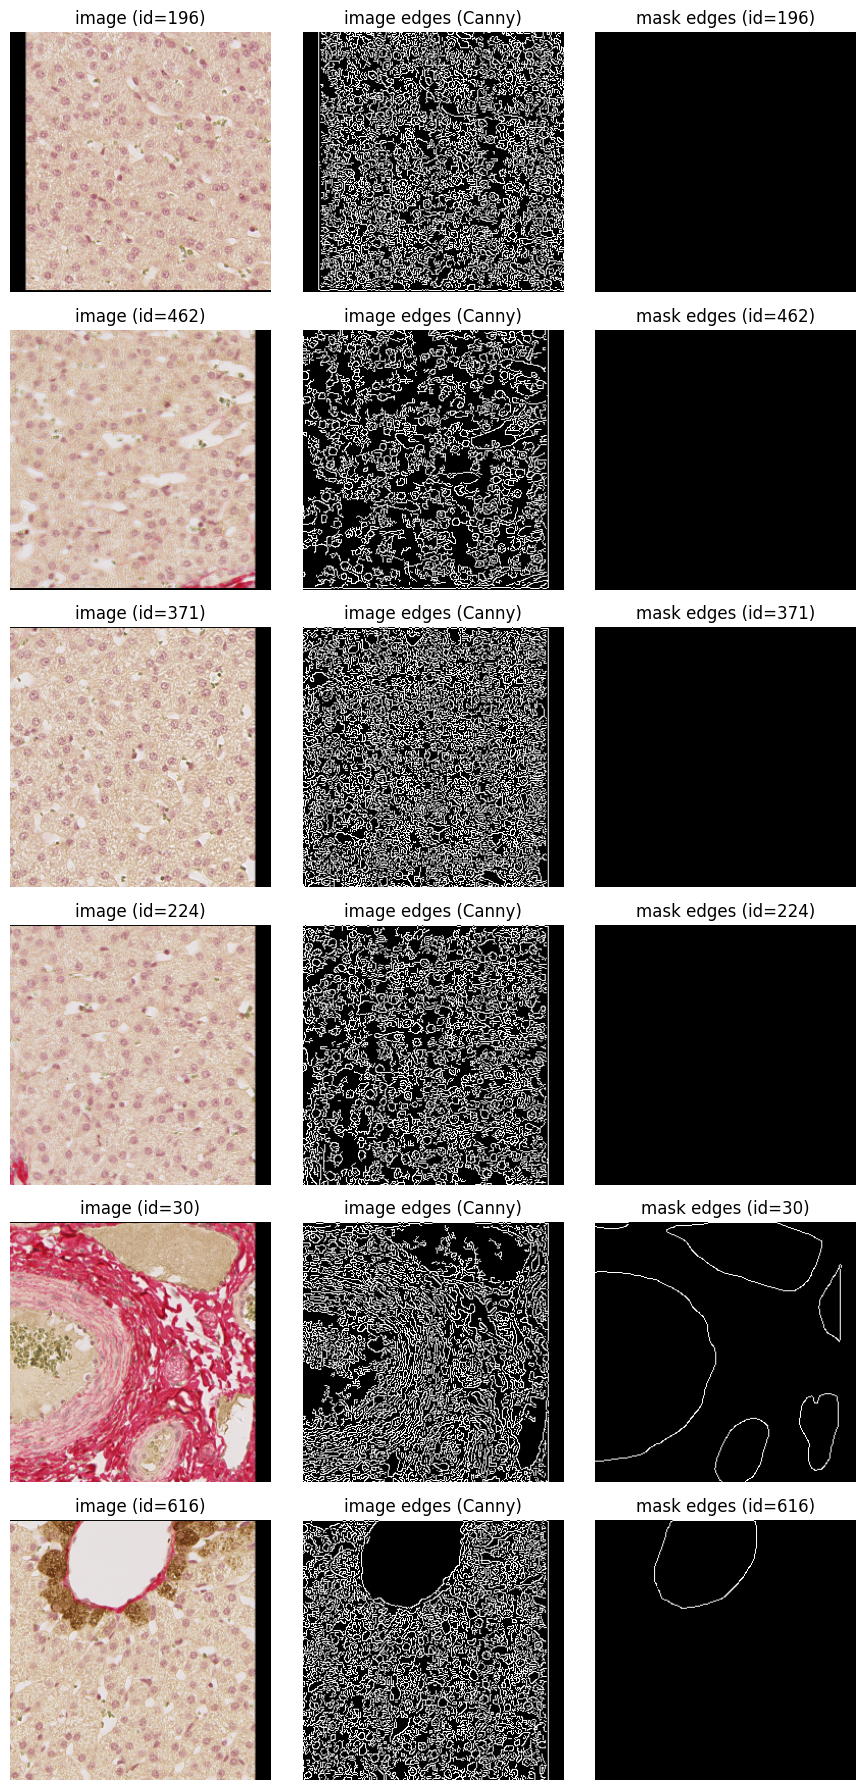

Look for: does the mask-edge column trace real structure in the image-edge column?
A mask edge that's a straight line / simple polygon with no relation to the image-edge
column is the Section 17 misalignment symptom, not a metrics or model problem.


In [11]:
import matplotlib.pyplot as plt

def quick_alignment_check(patch_path, mask_path, size=PATCH_SIZE):
    image, mask = load_pair(patch_path, mask_path, size=size)
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    img_edges = cv2.Canny(gray, 50, 150)
    mask_edges = cv2.Canny((mask * (255 // max(mask.max(), 1))).astype(np.uint8), 1, 1)
    return image, mask, img_edges, mask_edges

rng_check = np.random.default_rng(0)
check_idxs = rng_check.choice(len(test_ds), size=min(6, len(test_ds)), replace=False)

fig, axes = plt.subplots(len(check_idxs), 3, figsize=(9, 3 * len(check_idxs)))
for row, idx in enumerate(check_idxs):
    image, mask, img_edges, mask_edges = quick_alignment_check(test_patch_files[idx], test_mask_files[idx])
    axes[row, 0].imshow(image); axes[row, 0].set_title(f"image (id={numeric_id(test_patch_files[idx])})"); axes[row, 0].axis("off")
    axes[row, 1].imshow(img_edges, cmap="gray"); axes[row, 1].set_title("image edges (Canny)"); axes[row, 1].axis("off")
    axes[row, 2].imshow(mask_edges, cmap="gray"); axes[row, 2].set_title(f"mask edges (id={numeric_id(test_mask_files[idx])})"); axes[row, 2].axis("off")
plt.tight_layout()
plt.show()

print("Look for: does the mask-edge column trace real structure in the image-edge column?")
print("A mask edge that's a straight line / simple polygon with no relation to the image-edge")
print("column is the Section 17 misalignment symptom, not a metrics or model problem.")


## 3c. Fast checkpoint sanity check (before the full test loop)

Distinguishes two very different explanations for wrong-colored-but-
correctly-shaped predictions:
1. **Class-index ordering mismatch** -- the checkpoint's training-time
   color->index mapping doesn't match `CLASS_COLORS` here. Symptom: a clean
   permutation in the small confusion matrix below (a true class's pixels
   land heavily in one specific wrong column, not spread out).
2. **Undertrained / wrong checkpoint** -- symptom: predictions dominated by
   background pretty much everywhere, no clean off-diagonal pattern.

Runs on 16 patches only, so this takes seconds, not minutes.

In [12]:

import pandas as pd
import numpy as np
import random 
sanity_idxs = np.random.default_rng(1).choice(len(test_ds), size=min(16, len(test_ds)), replace=False)
sanity_confusion = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)
pred_pixel_counts = np.zeros(NUM_CLASSES, dtype=np.int64)
true_pixel_counts = np.zeros(NUM_CLASSES, dtype=np.int64)

model.eval()
with torch.no_grad():
    for idx in sanity_idxs:
        image, mask = load_pair(test_patch_files[idx], test_mask_files[idx])
        tensor_img = to_tensor(image).unsqueeze(0).to(device)
        with torch.cuda.amp.autocast():
            logits = model(tensor_img)
        pred = torch.argmax(logits, dim=1)[0].cpu().numpy()

        for pc in range(NUM_CLASSES):
            pred_pixel_counts[pc] += (pred == pc).sum()
            true_pixel_counts[pc] += (mask == pc).sum()
        flat_p, flat_t = pred.ravel(), mask.ravel()
        for pc, tc in zip(flat_p, flat_t):
            sanity_confusion[tc, pc] += 1

print("Predicted pixel share by class:", [round(x, 3) for x in pred_pixel_counts / pred_pixel_counts.sum()])
print("True pixel share by class     :", [round(x, 3) for x in true_pixel_counts / true_pixel_counts.sum()])
print()
sanity_df = pd.DataFrame(sanity_confusion, index=CLASS_NAMES, columns=CLASS_NAMES)
print("Confusion matrix (rows=true, cols=predicted), 16-patch sample:")
sanity_df


/tmp/ipykernel_58/3007963146.py:14: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


Predicted pixel share by class: [np.float64(0.95), np.float64(0.009), np.float64(0.025), np.float64(0.015), np.float64(0.002)]
True pixel share by class     : [np.float64(0.956), np.float64(0.007), np.float64(0.021), np.float64(0.013), np.float64(0.002)]

Confusion matrix (rows=true, cols=predicted), 16-patch sample:


,background,portal_vein,central_vein,artery,bile_duct
background,995377,1408,4279,1637,198
portal_vein,95,7716,0,0,0
central_vein,172,0,22189,0,0
artery,11,0,0,13737,0
bile_duct,232,0,0,0,1525


**How to read this:**
- If `background` in the predicted-share row is way higher than in the
  true-share row, **and** the confusion matrix shows true non-background
  classes scattered mostly into the `background` column with no other clear
  pattern → checkpoint (2), it's genuinely undertrained or the wrong file.
- If instead a true class (e.g. `bile_duct`) is landing heavily and
  specifically in one *other* class's column (e.g. almost all its pixels
  predicted as `central_vein`) → checkpoint (1), a class-order mismatch.
  In that case the fix is in how the checkpoint's training script assigned
  indices to colors, not in this notebook -- check that script's class order
  against `CLASS_COLORS` here and realign one side or the other.


## 3d. Targeted check: patches where bile_duct dominates

Section 3c showed background/portal_vein/central_vein/artery all predicted
correctly ~98-99.9% of the time, but ~99% of true bile_duct pixels predicted
as background -- and bile_duct pixels made up an unexpectedly large share
(~92%) of that random 16-patch sample, given it's supposed to be the rarest
class. Before concluding the model is just bad at bile_duct, pull the actual
patches responsible and look at them the same way as the Section 3b
alignment check: does the mask's purple region correspond to real duct
structure in the image, or is it a solid fill with no relationship to the
tissue (the Section 17 symptom)?

In [13]:
bile_duct_class = 4
bd_share_by_idx = []

def class_map_to_rgb(class_map, colors=CLASS_COLORS):
    return colors[class_map]

with torch.no_grad():
    for idx in sanity_idxs:
        _, mask = load_pair(test_patch_files[idx], test_mask_files[idx])
        share = (mask == bile_duct_class).mean()
        bd_share_by_idx.append((idx, share))

bd_share_by_idx.sort(key=lambda x: -x[1])
print("Sampled patch IDs ranked by fraction of pixels labeled bile_duct:")
for idx, share in bd_share_by_idx:
    print(f"  id={numeric_id(test_patch_files[idx])}  bile_duct_share={share:.3f}")


Sampled patch IDs ranked by fraction of pixels labeled bile_duct:
  id=540  bile_duct_share=0.025
  id=681  bile_duct_share=0.001
  id=684  bile_duct_share=0.001
  id=592  bile_duct_share=0.001
  id=601  bile_duct_share=0.000
  id=104  bile_duct_share=0.000
  id=226  bile_duct_share=0.000
  id=199  bile_duct_share=0.000
  id=25  bile_duct_share=0.000
  id=307  bile_duct_share=0.000
  id=187  bile_duct_share=0.000
  id=298  bile_duct_share=0.000
  id=338  bile_duct_share=0.000
  id=366  bile_duct_share=0.000
  id=180  bile_duct_share=0.000
  id=629  bile_duct_share=0.000


No sampled patches have >50% bile_duct share -- with the background-color fix
applied (Section 3, both black and white now map to class 0), this is expected
if the earlier bile_duct-heavy patches were mostly the white-background artifact.
Lowering the threshold to just show whatever bile_duct content exists, if any:


/tmp/ipykernel_58/3126642233.py:21: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


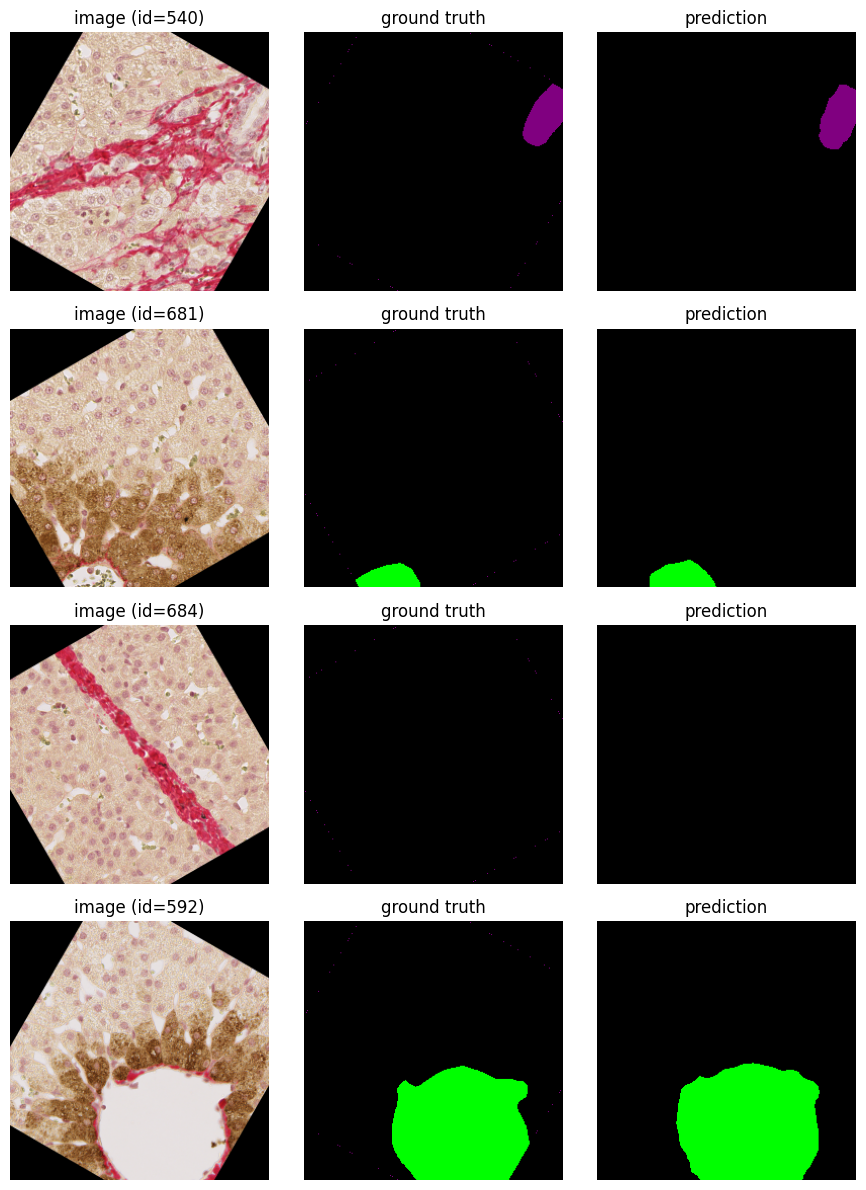

If the ground-truth column is a solid purple fill with no visible duct structure
in the corresponding image, that's a data problem (Section 17-style), not a model
problem -- the model correctly refused to hallucinate duct tissue that isn't there.


In [14]:
top_bd_idxs = [idx for idx, share in bd_share_by_idx if share > 0.5][:4]

if len(top_bd_idxs) == 0:
    print("No sampled patches have >50% bile_duct share -- with the background-color fix")
    print("applied (Section 3, both black and white now map to class 0), this is expected")
    print("if the earlier bile_duct-heavy patches were mostly the white-background artifact.")
    print("Lowering the threshold to just show whatever bile_duct content exists, if any:")
    top_bd_idxs = [idx for idx, share in bd_share_by_idx if share > 0][:4]

if len(top_bd_idxs) == 0:
    print("None of the sampled patches contain any bile_duct pixels at all -- skipping this plot.")
else:
    fig, axes = plt.subplots(len(top_bd_idxs), 3, figsize=(9, 3 * len(top_bd_idxs)))
    if len(top_bd_idxs) == 1:
        axes = axes[None, :]

    for row, idx in enumerate(top_bd_idxs):
        image, mask = load_pair(test_patch_files[idx], test_mask_files[idx])
        tensor_img = to_tensor(image).unsqueeze(0).to(device)
        with torch.no_grad():
            with torch.cuda.amp.autocast():
                logits = model(tensor_img)
            pred = torch.argmax(logits, dim=1)[0].cpu().numpy()

        axes[row, 0].imshow(image); axes[row, 0].set_title(f"image (id={numeric_id(test_patch_files[idx])})"); axes[row, 0].axis("off")
        axes[row, 1].imshow(class_map_to_rgb(mask)); axes[row, 1].set_title("ground truth"); axes[row, 1].axis("off")
        axes[row, 2].imshow(class_map_to_rgb(pred)); axes[row, 2].set_title("prediction"); axes[row, 2].axis("off")

    plt.tight_layout()
    plt.show()

    print("If the ground-truth column is a solid purple fill with no visible duct structure")
    print("in the corresponding image, that's a data problem (Section 17-style), not a model")
    print("problem -- the model correctly refused to hallucinate duct tissue that isn't there.")

## 3e. Full-test-set check: how many masks are degenerate (single class only)?

9 of 16 sampled patches came back with `bile_duct_share == 1.000` exactly --
not close to 1, exactly 1. Real 256x256 histology patches essentially never
have zero background/other tissue visible. That's unlikely to be genuine
biological variation and looks like a systematic artifact. This check reads
every mask in `Testing/` (no model inference needed, so it's fast) and counts
how many are single-class-only, broken down by which class.

In [15]:
from collections import Counter

degenerate_counts = Counter()
degenerate_examples = {c: [] for c in range(NUM_CLASSES)}

for path in test_mask_files:
    mask_bgr = cv2.imread(path, cv2.IMREAD_COLOR)
    mask_rgb = cv2.cvtColor(mask_bgr, cv2.COLOR_BGR2RGB)
    mask_small = cv2.resize(mask_rgb, (PATCH_SIZE, PATCH_SIZE), interpolation=cv2.INTER_NEAREST)
    class_map = rgb_mask_to_class_index(mask_small)
    uniques = np.unique(class_map)
    if len(uniques) == 1:
        c = int(uniques[0])
        degenerate_counts[c] += 1
        if len(degenerate_examples[c]) < 5:
            degenerate_examples[c].append(numeric_id(path))

total = len(test_mask_files)
n_degenerate = sum(degenerate_counts.values())
print(f"Total test masks: {total}")
print(f"Single-class (degenerate) masks: {n_degenerate}  ({100*n_degenerate/total:.1f}%)")
print()
for c in range(NUM_CLASSES):
    n = degenerate_counts.get(c, 0)
    if n:
        print(f"  {CLASS_NAMES[c]:>13}: {n:4d} masks ({100*n/total:.1f}%)  e.g. ids {degenerate_examples[c]}")


Total test masks: 728
Single-class (degenerate) masks: 316  (43.4%)

     background:  316 masks (43.4%)  e.g. ids [4, 5, 6, 8, 9]


## 3f-prep. Define Training/ paths
These were never defined anywhere in this notebook (it only ever set up `TEST_PATCH_DIR`/`TEST_MASK_DIR` in Cell 5) -- added here since the Training/ check below depends on them.

In [16]:
TRAIN_PATCH_DIR = os.path.join(DATASET_ROOT, "Training", "patches")
TRAIN_MASK_DIR  = os.path.join(DATASET_ROOT, "Training", "masks")
print("train patches:", len(glob.glob(os.path.join(TRAIN_PATCH_DIR, "*.tiff"))))
print("train masks  :", len(glob.glob(os.path.join(TRAIN_MASK_DIR, "*.tiff"))))

train patches: 6544
train masks  : 6544


## 3f. Are the degenerate masks clustered, and does Training/ have the same issue?

44.8% single-class (all bile_duct) is too large to be a rare fluke -- this is
a real, previously undiscovered data-quality issue in vessel's `Testing/`
split, the same category of problem Section 17 describes for lobule.

Two follow-ups before deciding what to do about it:
1. **Clustering** -- contiguous degenerate IDs point to something systematic
   (a bad export batch, an overwritten range) rather than scattered random
   corruption.
2. **Does `Training/` have the same issue?** This is the more urgent
   question -- if it does, the already-reported Runs 1-3 val_dice numbers for
   bile_duct (0.615-0.621) may be partly computed against the same corrupted
   labels, not just this test-set evaluation.

In [17]:
degenerate_ids = []
for path in test_mask_files:
    mask_bgr = cv2.imread(path, cv2.IMREAD_COLOR)
    mask_rgb = cv2.cvtColor(mask_bgr, cv2.COLOR_BGR2RGB)
    mask_small = cv2.resize(mask_rgb, (PATCH_SIZE, PATCH_SIZE), interpolation=cv2.INTER_NEAREST)
    class_map = rgb_mask_to_class_index(mask_small)
    if len(np.unique(class_map)) == 1 and class_map[0, 0] == 4:  # bile_duct-only
        degenerate_ids.append(numeric_id(path))

degenerate_ids.sort()
print(f"{len(degenerate_ids)} degenerate (bile_duct-only) test mask IDs")
print("First 30:", degenerate_ids[:30])
print("Last 10 :", degenerate_ids[-10:])

# Gap analysis: are they mostly contiguous runs, or scattered through the ID range?
gaps = np.diff(degenerate_ids)
run_lengths = []
current_run = 1
for g in gaps:
    if g == 1:
        current_run += 1
    else:
        run_lengths.append(current_run)
        current_run = 1
run_lengths.append(current_run)

print(f"\nNumber of contiguous runs: {len(run_lengths)}")
print(f"Longest contiguous run: {max(run_lengths)} consecutive IDs")
print(f"Mean run length: {np.mean(run_lengths):.1f}")
print(f"ID range overall: {min(degenerate_ids)} to {max(degenerate_ids)} (test set spans {min(numeric_id(p) for p in test_mask_files)} to {max(numeric_id(p) for p in test_mask_files)})")


0 degenerate (bile_duct-only) test mask IDs
First 30: []
Last 10 : []

Number of contiguous runs: 1
Longest contiguous run: 1 consecutive IDs
Mean run length: 1.0


ValueError: min() iterable argument is empty

In [ ]:
# Same check against Training/ -- more important than the test-set finding,
# since it's what Runs 1-3's already-reported val_dice numbers were computed on.
train_mask_files_check = glob.glob(os.path.join(TRAIN_MASK_DIR, "mask_*.tiff"))
print(f"Scanning {len(train_mask_files_check)} training masks (this reads every file -- may take a minute)...")

train_degenerate_counts = Counter()
for path in train_mask_files_check:
    mask_bgr = cv2.imread(path, cv2.IMREAD_COLOR)
    mask_rgb = cv2.cvtColor(mask_bgr, cv2.COLOR_BGR2RGB)
    mask_small = cv2.resize(mask_rgb, (PATCH_SIZE, PATCH_SIZE), interpolation=cv2.INTER_NEAREST)
    class_map = rgb_mask_to_class_index(mask_small)
    uniques = np.unique(class_map)
    if len(uniques) == 1:
        train_degenerate_counts[int(uniques[0])] += 1

train_total = len(train_mask_files_check)
train_n_degenerate = sum(train_degenerate_counts.values())
print(f"\nTraining masks: {train_total}")
print(f"Single-class (degenerate) training masks: {train_n_degenerate}  ({100*train_n_degenerate/train_total:.1f}%)")
for c in range(NUM_CLASSES):
    n = train_degenerate_counts.get(c, 0)
    if n:
        print(f"  {CLASS_NAMES[c]:>13}: {n:4d} masks ({100*n/train_total:.1f}%)")


## 4. Metrics — Dice, IoU, TPR, ASSD, confusion matrix (Section 12)

In [ ]:
from scipy.ndimage import distance_transform_edt, binary_erosion

def dice_iou_tpr_per_class(pred, target, num_classes=NUM_CLASSES, smooth=1e-6):
    """pred, target: (N,H,W) int arrays for one batch."""
    dices, ious, tprs = [], [], []
    for c in range(num_classes):
        p = (pred == c)
        t = (target == c)
        inter = np.logical_and(p, t).sum()
        union = np.logical_or(p, t).sum()
        dice = (2 * inter + smooth) / (p.sum() + t.sum() + smooth)
        iou = (inter + smooth) / (union + smooth)
        tpr = (inter + smooth) / (t.sum() + smooth)  # sensitivity / recall
        dices.append(dice); ious.append(iou); tprs.append(tpr)
    return dices, ious, tprs


def _boundary(mask_bool):
    if mask_bool.sum() == 0:
        return mask_bool
    eroded = binary_erosion(mask_bool)
    return mask_bool & ~eroded


def assd_per_class(pred, target, num_classes=NUM_CLASSES, um_per_px=UM_PER_PX):
    """Average symmetric surface distance, per class, for ONE image (H,W arrays).
    Returns NaN for a class if it's absent from both pred and target in this image
    (skip that image for that class when averaging across the set)."""
    result = []
    for c in range(num_classes):
        p = (pred == c)
        t = (target == c)
        if p.sum() == 0 and t.sum() == 0:
            result.append(np.nan)
            continue
        if p.sum() == 0 or t.sum() == 0:
            # one has the structure, the other doesn't -- treat as a large but finite
            # penalty rather than skipping, so a totally-missed class is penalized.
            result.append(np.nan)
            continue
        p_b, t_b = _boundary(p), _boundary(t)
        dt_t = distance_transform_edt(~t_b)
        dt_p = distance_transform_edt(~p_b)
        d_pt = dt_t[p_b]   # distance from each predicted-boundary pixel to nearest GT-boundary pixel
        d_tp = dt_p[t_b]   # distance from each GT-boundary pixel to nearest predicted-boundary pixel
        assd_px = (d_pt.sum() + d_tp.sum()) / (len(d_pt) + len(d_tp))
        result.append(assd_px * um_per_px)
    return result


In [ ]:
confusion = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)
all_dice, all_iou, all_tpr, all_assd = [], [], [], []

model.eval()
with torch.no_grad():
    for images, masks, idxs in test_loader:
        images = images.to(device)
        with torch.cuda.amp.autocast():
            logits = model(images)
        preds = torch.argmax(logits, dim=1).cpu().numpy()
        targets = masks.numpy()

        d, i, t = dice_iou_tpr_per_class(preds, targets)
        all_dice.append(d); all_iou.append(i); all_tpr.append(t)

        for b in range(preds.shape[0]):
            all_assd.append(assd_per_class(preds[b], targets[b]))
            flat_p, flat_t = preds[b].ravel(), targets[b].ravel()
            for pc, tc in zip(flat_p, flat_t):
                confusion[tc, pc] += 1

mean_dice = np.mean(all_dice, axis=0)
mean_iou = np.mean(all_iou, axis=0)
mean_tpr = np.mean(all_tpr, axis=0)
mean_assd = np.nanmean(all_assd, axis=0)  # nan-safe: some classes absent in some patches

print("Per-class metrics (background/portal_vein/central_vein/artery/bile_duct):")
print("Dice:", [round(x, 3) for x in mean_dice])
print("IoU :", [round(x, 3) for x in mean_iou])
print("TPR :", [round(x, 3) for x in mean_tpr])
print("ASSD (um):", [round(x, 3) if not np.isnan(x) else None for x in mean_assd])


## 5. Save metrics + confusion matrix

In [ ]:
import pandas as pd

metrics_df = pd.DataFrame({
    "class": CLASS_NAMES,
    "dice": mean_dice,
    "iou": mean_iou,
    "tpr": mean_tpr,
    "assd_um": mean_assd,
})
metrics_df.to_csv(os.path.join(RESULTS_DIR, "deeplabv3plus_vessel_test_metrics.csv"), index=False)

confusion_df = pd.DataFrame(confusion, index=CLASS_NAMES, columns=CLASS_NAMES)
confusion_df.to_csv(os.path.join(RESULTS_DIR, "deeplabv3plus_vessel_confusion_matrix.csv"))

summary = {
    "model": "DeepLabV3+",
    "encoder": ENCODER_NAME,
    "checkpoint": CHECKPOINT_PATH,
    "dataset": "vessel",
    "split": "Testing (held-out)",
    "n_test_pairs": len(test_ds),
    "um_per_px": UM_PER_PX,
}
with open(os.path.join(RESULTS_DIR, "run_summary.json"), "w") as f:
    json.dump(summary, f, indent=2)

metrics_df


## 6. Visual spot-check — a few image / ground-truth / prediction triplets

In [ ]:
import matplotlib.pyplot as plt

CLASS_COLORS_DISPLAY = CLASS_COLORS  # same palette, for rendering predicted class maps

def class_map_to_rgb(class_map, colors=CLASS_COLORS_DISPLAY):
    return colors[class_map]

n_show = 4
rng = np.random.default_rng(42)
sample_idxs = rng.choice(len(test_ds), size=min(n_show, len(test_ds)), replace=False)

fig, axes = plt.subplots(len(sample_idxs), 3, figsize=(9, 3 * len(sample_idxs)))
if len(sample_idxs) == 1:
    axes = axes[None, :]

for row, idx in enumerate(sample_idxs):
    image, mask = load_pair(test_patch_files[idx], test_mask_files[idx])
    tensor_img = to_tensor(image).unsqueeze(0).to(device)
    with torch.no_grad():
        with torch.cuda.amp.autocast():
            logits = model(tensor_img)
        pred = torch.argmax(logits, dim=1)[0].cpu().numpy()

    axes[row, 0].imshow(image); axes[row, 0].set_title("image"); axes[row, 0].axis("off")
    axes[row, 1].imshow(class_map_to_rgb(mask)); axes[row, 1].set_title("ground truth"); axes[row, 1].axis("off")
    axes[row, 2].imshow(class_map_to_rgb(pred)); axes[row, 2].set_title("DeepLabV3+ prediction"); axes[row, 2].axis("off")

plt.tight_layout()
fig_path = os.path.join(RESULTS_DIR, "sample_predictions.png")
plt.savefig(fig_path, dpi=150)
plt.show()
print("saved:", fig_path)


## 7. Zip results for manual Drive merge

No Kaggle to Drive integration (Section 11) -- zip, download from the Output
panel, then drop into the shared Drive folder alongside the other runs'
results.

In [ ]:
zip_path = "/kaggle/working/deeplabv3plus_vessel_inference_results.zip"
!zip -r {zip_path} {RESULTS_DIR}
print("Zipped. Download deeplabv3plus_vessel_inference_results.zip from the Output panel.")


---
**Note on the comparison table (Section 8 / Section 13):** the project guide's
run matrix currently only tracks Runs 1-6 (vessel Runs 1-3, lobule Runs 4-6),
now plus the SegFormer run built earlier. If DeepLabV3+ is meant to be a
permanent row in the final comparison table, add it to that matrix explicitly
rather than leaving it implicit — same as the note left on the SegFormer
notebook.
